# Step 3 — WS-1 · Q1: *When does CSI decide to bid?*
Binary classifier for `CSI_Participated` over **all 1,591 projects**.

🔒 **Leakage guard (the important methodological call):** features must be
knowable from the RFP **before** CSI decides. We **exclude** realized
competition (`Num_Valid_Bidders`, market tightness) and all post-auction
outcomes — CSI can't see those at decision time. Using them would be cheating
(and violates project Hard Rule 10).

In [1]:
from pathlib import Path
import warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)  # spurious BLAS matmul noise on this machine
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 40)

# --- Absolute paths (edit BASE if you move the project) -----------------------
BASE   = Path("/Users/t/Library/Mobile Documents/com~apple~CloudDocs/00 MSBA + Coding/00_summer 2026/00_CSI_ELP/01_Summer_2026")
MASTER = BASE / "2026-06-03_csi_bid_master.csv"          # raw source (read-only)
OUT    = BASE / "06_sweetspot" / "outputs"               # intermediates + figures
OUT.mkdir(parents=True, exist_ok=True)
MAT = ["MIX_TN","GRADE_CY","BASE_TN","SHLDR_TN","MILL_SY","CRUSH_TN","STOCK_TN"]
print("paths OK |", MASTER.name, "exists:", MASTER.exists())

paths OK | 2026-06-03_csi_bid_master.csv exists: True


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

base = pd.read_csv(OUT/"2026-06-04_project_base.csv")
arch = pd.read_csv(OUT/"2026-06-04_project_archetypes.csv")
df = base.merge(arch, on="Contract_Id", how="left")

### Build the feature set (RFP-knowable only)
`log_size` because project value spans $3 → $168M (log keeps mega-projects from
dominating). One-hots for `State` and `rule_archetype`. Complexity flags `BOX` /
prevailing wages. Material proportions = the job's shape.

In [3]:
def build_features(df):
    df = df.copy()
    df["log_size"] = np.log10(df["Project_Size_Dollars"].clip(lower=1))
    df["BOX_i"]   = df["BOX"].astype(int)
    df["PW_yes"]  = (df["PREVAILING_WAGES"]==True).astype(int)
    df["PW_unknown"] = df["PREVAILING_WAGES"].isna().astype(int)
    df["has_quantity_i"] = df["has_quantity"].astype(int)
    for p in ["prop_MIX_TN","prop_GRADE_CY","prop_BASE_TN","prop_SHLDR_TN","prop_MILL_SY","prop_STOCK_TN"]:
        df[p] = df[p].fillna(0.0)
    df["State"] = df["State"].fillna("UNK")
    return df
df = build_features(df)
y = (df["CSI_Participated"]==True).astype(int).values
NUM = ["log_size","n_mat_types","BOX_i","PW_yes","PW_unknown","prop_MIX_TN","prop_GRADE_CY",
       "prop_BASE_TN","prop_SHLDR_TN","prop_MILL_SY","prop_STOCK_TN","has_quantity_i"]
CAT = ["State","rule_archetype"]
print("CSI bid:", y.sum(), f"({y.mean()*100:.1f}%)  | features:", len(NUM)+len(CAT))

CSI bid: 603 (37.9%)  | features: 14


### Train + evaluate (5-fold cross-validation)
We compare interpretable **logistic regression** vs **gradient boosting**.
- **ROC-AUC**: ranking quality (0.5 = coin flip, 1.0 = perfect).
- **PR-AUC**: precision under class imbalance (baseline = the 38% bid rate).

In [4]:
pre = ColumnTransformer([
    ("num", Pipeline([("imp",SimpleImputer(strategy="median")),("sc",StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CAT)])
cv = StratifiedKFold(5, shuffle=True, random_state=42)
for name, clf in [("logistic", LogisticRegression(max_iter=2000, class_weight="balanced")),
                  ("hist_gb",  HistGradientBoostingClassifier(random_state=42))]:
    p = cross_val_predict(Pipeline([("pre",pre),("clf",clf)]), df, y, cv=cv, method="predict_proba")[:,1]
    print(f"{name:9s} ROC-AUC={roc_auc_score(y,p):.3f}  PR-AUC={average_precision_score(y,p):.3f}  (base PR={y.mean():.3f})")

logistic  ROC-AUC=0.659  PR-AUC=0.523  (base PR=0.379)


hist_gb   ROC-AUC=0.703  PR-AUC=0.589  (base PR=0.379)


### What drives the bid decision? (permutation importance)
We shuffle each feature and measure the drop in ROC-AUC — bigger drop = more
important. Model-agnostic and honest about *predictive* contribution.

In [5]:
Xsub = df[NUM+CAT]
best = Pipeline([("pre",pre),("clf",HistGradientBoostingClassifier(random_state=42))]).fit(Xsub, y)
r = permutation_importance(best, Xsub, y, n_repeats=10, random_state=42, scoring="roc_auc")
imp = pd.DataFrame({"feature":NUM+CAT,"importance":r.importances_mean}).sort_values("importance", ascending=False)
imp.to_csv(OUT/"2026-06-04_bid_model_importance.csv", index=False); imp

,feature,importance
0,log_size,0.154011
12,State,0.117890
13,rule_archetype,0.061018
7,prop_BASE_TN,0.059288
5,prop_MIX_TN,0.046075
6,prop_GRADE_CY,0.039536
9,prop_MILL_SY,0.035535
3,PW_yes,0.008704
8,prop_SHLDR_TN,0.007391
1,n_mat_types,0.004612


### P(CSI bids | archetype) — the revealed-preference table

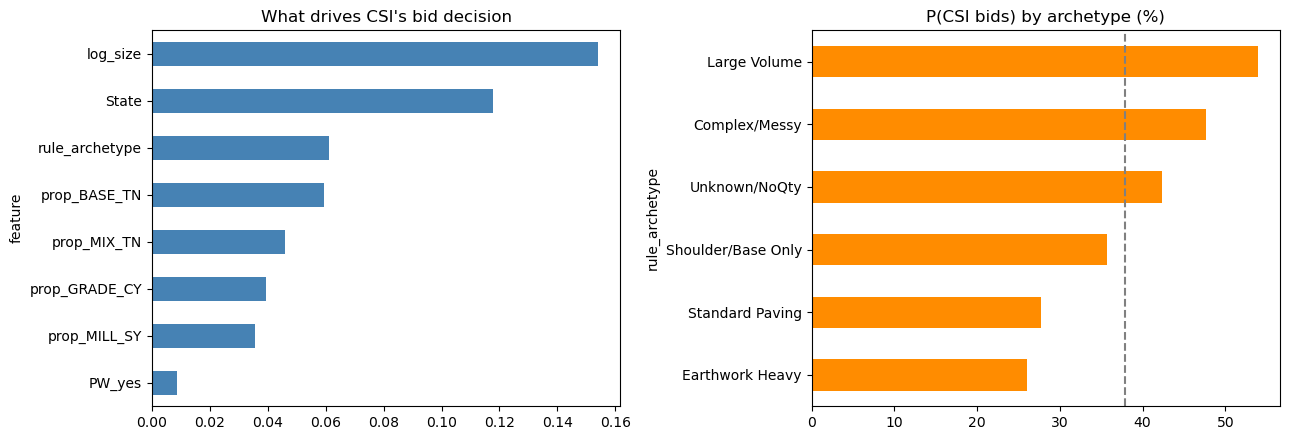

,n,bid_rate
rule_archetype,,
Large Volume,319,53.9
Complex/Messy,227,47.6
Unknown/NoQty,215,42.3
Shoulder/Base Only,84,35.7
Standard Paving,484,27.7
Earthwork Heavy,262,26.0


In [6]:
g = (df.groupby("rule_archetype")["CSI_Participated"]
       .agg(n="size", bid_rate=lambda s:(s==True).mean()*100).round(1)
       .sort_values("bid_rate", ascending=False))
g.to_csv(OUT/"2026-06-04_bid_by_archetype.csv")
fig, ax = plt.subplots(1,2, figsize=(13,4.5))
imp.head(8).iloc[::-1].plot.barh(x="feature", y="importance", ax=ax[0], legend=False, color="steelblue")
ax[0].set_title("What drives CSI's bid decision")
g["bid_rate"].sort_values().plot.barh(ax=ax[1], color="darkorange")
ax[1].axvline(y.mean()*100, ls="--", c="gray"); ax[1].set_title("P(CSI bids) by archetype (%)")
plt.tight_layout(); plt.show()
g

**Takeaway:** the bid decision is moderately predictable (**AUC 0.70**),
driven by **size → geography → archetype**. CSI bids most on **Large Volume
(54%)** and **Complex/Messy (48%)** — its stated edge shows up in its behavior.